# 02. Final basin set: glaciers inside CAMELS-CL gauged basins

Builds, checks and saves the basin set used for all glacier-streamflow analysis (strategy C).

**How the basins are chosen**
1. Start from the CAMELS-CL basins that contain at least one RGI glacier.
2. Keep the largest basins, meaning those not contained in any other basin.
3. If the gauge of a largest basin fails the streamflow checks, use the basins nested directly inside it instead, and go one level further in where those also fail.
4. A glacier outside all usable basins is left out. Every glacier is in one basin at most.

**Expected numbers (check them when you run it):** 266 glacierized basins with 6,883 glaciers, 41 largest basins, 143 gauges passing the completeness criteria, 40 final basins with 6,577 glaciers.

**Saves to** `Output/final_basin_set/`: `final_basin_table.csv`, `glacier_assignment.csv`, `final_basins.gpkg`. Notebook 03 and later read these files.

Not included on purpose: the comparison of basin groupings, the nesting and glacier-fraction cutoff tests, and the Caro catchment comparison. Those stay in the archived notebooks.

## 1. Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import sys
sys.path.insert(0, '/Users/milliespencer/OGGM_CR2_Chile')
from completeness_utils import assess_completeness, LAT_BOUNDARY   # one shared definition of the criteria
warnings.filterwarnings('ignore')

BASE_PATH   = '/Users/milliespencer/v2_CR2_OGGM_project_11_2026'
CAMELS_FULL = f'{BASE_PATH}/Full_CAMELS_all_basins/CAMELS_CL_v202201'
BOUNDS_PATH = f'{CAMELS_FULL}/camels_cl_boundaries/camels_cl_boundaries.shp'
Q_DAY_PATH  = f'{CAMELS_FULL}/q_m3s_day.csv'
RGI_PATH    = f'{BASE_PATH}/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv'
OUT_DIR     = f'{BASE_PATH}/Output/final_basin_set'
os.makedirs(OUT_DIR, exist_ok=True)

AREA_CRS    = 'ESRI:102033'    # South America Albers equal area, for areas
CONTAIN_MIN = 0.9              # a basin is "inside" another if >= this fraction of it is (the result does not depend on this)


ZONES = ['OT3', 'DA1', 'DA2', 'DA3', 'WA1', 'WA2', 'WA3', 'WA4', 'WA5', 'WA6']
ZC = {'OT3': '#8c564b', 'DA1': '#e377c2', 'DA2': '#7f7f7f', 'DA3': '#bcbd22', 'WA1': '#17becf',
      'WA2': '#2ca02c', 'WA3': '#d62728', 'WA4': '#1f77b4', 'WA5': '#ff7f0e', 'WA6': '#9467bd'}

for p in [BOUNDS_PATH, Q_DAY_PATH, RGI_PATH]:
    print(f'{os.path.exists(p)}  {p}')

True  /Users/milliespencer/v2_CR2_OGGM_project_11_2026/Full_CAMELS_all_basins/CAMELS_CL_v202201/camels_cl_boundaries/camels_cl_boundaries.shp
True  /Users/milliespencer/v2_CR2_OGGM_project_11_2026/Full_CAMELS_all_basins/CAMELS_CL_v202201/q_m3s_day.csv
True  /Users/milliespencer/v2_CR2_OGGM_project_11_2026/files_chile_OGGM_climate_comparison/RGI_BNA_Clusters.csv


## 2. Load basins and glaciers

Each glacier is placed in a basin by its RGI centroid. A glacier sits in every basin that contains it (CAMELS-CL basins are cumulative, so smaller basins sit inside larger ones).

In [2]:
# CAMELS-CL basins
bounds_all = gpd.read_file(BOUNDS_PATH)
bounds_all['gauge_id'] = bounds_all['gauge_id'].astype(str)
bounds_all = bounds_all.to_crs(AREA_CRS)
bounds_all['geometry'] = bounds_all.buffer(0)
bounds_all['area_km2_poly'] = bounds_all.geometry.area / 1e6
if 'gauge_name' not in bounds_all.columns:
    bounds_all['gauge_name'] = ''
names = bounds_all.set_index('gauge_id')['gauge_name'].to_dict()

# RGI glaciers (centroids) with their zone
rgi = pd.read_csv(RGI_PATH)
gl = gpd.GeoDataFrame(rgi[['RGIId', 'Area', 'Cluster', 'TermType', 'CenLat']].copy(),
                      geometry=gpd.points_from_xy(rgi.CenLon, rgi.CenLat),
                      crs='EPSG:4326').to_crs(AREA_CRS)
gl['Cluster'] = gl['Cluster'].astype(str)

# glacier -> every basin that contains it (land-terminating glaciers only; calving glaciers are not simulated)
pj = gpd.sjoin(gl.loc[gl['TermType'] == 0, ['Area', 'Cluster', 'CenLat', 'geometry']],   # CHANGED: TermType == 0
               bounds_all[['gauge_id', 'area_km2_poly', 'geometry']],
               how='inner', predicate='within')
pj['gid'] = pj.index
pj = pj.reset_index(drop=True)
members = pj.groupby('gauge_id')['gid'].apply(list).to_dict()     # basin -> glaciers inside it

# basins that contain at least one glacier
cm = bounds_all[bounds_all['gauge_id'].isin(set(pj['gauge_id']))].copy().reset_index(drop=True)
area = cm.set_index('gauge_id')['area_km2_poly']
lat = pj.groupby('gauge_id')['CenLat'].mean()      # mean glacier latitude of each basin (decides the 38S rule)

print(f'CAMELS-CL basins: {len(bounds_all)} | glaciers (RGI): {len(gl):,} | glacier area: {gl["Area"].sum():,.0f} km2')
print(f'Basins containing glaciers: {len(cm)} (expected 266)')
print(f'Glaciers inside at least one basin: {pj["gid"].nunique():,} (expected 6,883)')

CAMELS-CL basins: 516 | glaciers (RGI): 13,246 | glacier area: 27,499 km2
Basins containing glaciers: 266 (expected 266)
Glaciers inside at least one basin: 6,852 (expected 6,883)


## 3. Table 1: glaciers by zone, and how many are inside a gauged basin

"Gauged" means inside a CAMELS-CL basin, before the streamflow completeness criteria. Calving glaciers are lake-terminating or marine-terminating (RGI TermType 2 or 1).

In [3]:
g = gl.copy()
g['gauged'] = g.index.isin(pj['gid'])
g['area_gauged'] = g['Area'].where(g['gauged'], 0)
g['calving'] = g['TermType'].isin([1, 2])

table1 = g.groupby('Cluster').agg(glaciers=('Area', 'size'),
                                  area_km2=('Area', 'sum'),
                                  gauged_glaciers=('gauged', 'sum'),
                                  gauged_area_km2=('area_gauged', 'sum'),
                                  calving_glaciers=('calving', 'sum')).reindex(ZONES)
table1.loc['All'] = table1.sum()
table1['pct_glaciers'] = 100 * table1['gauged_glaciers'] / table1['glaciers']
table1['pct_area'] = 100 * table1['gauged_area_km2'] / table1['area_km2']
print(table1.round(0).astype({'glaciers': int, 'gauged_glaciers': int, 'calving_glaciers': int}).to_string())
table1.to_csv(f'{OUT_DIR}/table1_glaciers_by_zone.csv')

         glaciers  area_km2  gauged_glaciers  gauged_area_km2  calving_glaciers  pct_glaciers  pct_area
Cluster                                                                                                
OT3            34      13.0               32             13.0                 0          94.0      95.0
DA1           422     148.0              400            140.0                 0          95.0      94.0
DA2           200     254.0              196            253.0                 0          98.0     100.0
DA3           410     391.0              408            390.0                 0         100.0     100.0
WA1           678     308.0              669            307.0                 0          99.0     100.0
WA2          2924    1738.0             1927            923.0                 4          66.0      53.0
WA3           447   10947.0              102            123.0                47          23.0       1.0
WA4          4749    6474.0             3068           2412.0   

## 4. Nesting between basins

An arrow a -> b means basin a is inside basin b. Largest basins are the ones with no arrow leaving them.

In [4]:
cmv = cm[['gauge_id', 'geometry']]
pairs = gpd.overlay(cmv.rename(columns={'gauge_id': 'a'}), cmv.rename(columns={'gauge_id': 'b'}),
                    how='intersection')
pairs = pairs[pairs['a'] != pairs['b']].copy()
pairs['frac_a_in_b'] = (pairs.geometry.area / 1e6) / pairs['a'].map(area)
pairs = pairs[(pairs['frac_a_in_b'] >= CONTAIN_MIN) & (pairs['a'].map(area) < pairs['b'].map(area))]

G = nx.DiGraph()
G.add_nodes_from(cm['gauge_id'])
G.add_edges_from(zip(pairs['a'], pairs['b']))       # a -> b: a is inside b
H = nx.transitive_reduction(G)                      # direct containment only

terminal = {n for n in G.nodes if G.out_degree(n) == 0}     # largest basins
finest   = {n for n in G.nodes if G.in_degree(n) == 0}      # basins with nothing inside
print(f'Largest basins (not inside any other): {len(terminal)} (expected 41)')
print(f'Finest basins (nothing inside them):   {len(finest)}')

Largest basins (not inside any other): 41 (expected 41)
Finest basins (nothing inside them):   103


## 5. Streamflow completeness criteria

The criteria are in `completeness_utils.py` (one definition for the whole repo). A year is complete if December (previous year) to April each have at least 70% valid days and at least 4 of the 7 months May to November have at least 50%. North of 38°S a basin needs 5 complete years in each of 2000-2009 and 2010-2019. South of 38°S it needs 10 complete years in 2000-2019. The latitude used is the mean latitude of the basin's glaciers.

In [5]:
q_day = pd.read_csv(Q_DAY_PATH, parse_dates=['date'])
q_day = q_day[(q_day['year'] >= 1999) & (q_day['year'] <= 2019)].copy()

rows = []
for g in cm['gauge_id']:
    c = assess_completeness(q_day, g, lat[g])
    rows.append(dict(gauge_id=g, lat=lat[g], n_complete_years=c['n_complete'], n_2000_2009=c['n_pre2010'],
                     n_2010_2019=c['n_post2010'], passes=c['passes'], reason=c['reason']))
completeness = pd.DataFrame(rows).set_index('gauge_id')
completeness.to_csv(f'{OUT_DIR}/completeness_by_gauge.csv')

VALID_IDS = set(completeness.index[completeness['passes']])
print(f'Pass completeness: {len(VALID_IDS)} of {len(cm)} glacierized basins (expected 143)')
print(f'  largest basins that pass: {len(VALID_IDS & terminal)} of {len(terminal)} (expected 27 of 41)')
print('Largest basins that fail:', sorted(terminal - VALID_IDS))

Pass completeness: 143 of 266 glacierized basins (expected 143)
  largest basins that pass: 27 of 41 (expected 27 of 41)
Largest basins that fail: ['10122001', '1021001', '10683002', '11130001', '11147001', '11151001', '11405001', '12825002', '2120001', '3453001', '3826001', '4335001', '5423005', '6019003']


## 6. Basins to leave out by hand

Empty by default. A basin listed here is treated like one that fails the completeness criteria: its sub-basins are used instead, going further in as needed.

Use it after notebook 03 has run the check for months where modeled glacier runoff is greater than measured streamflow. Put the gauge IDs that check removes here (for example the Maipo gauges 5702001 and 5706001, pending Alexis's review), then rerun this notebook and notebook 03.

In [6]:
EXTRA_EXCLUDE = set()      # e.g. {'5702001', '5706001'}

valid_final = (VALID_IDS - set(EXTRA_EXCLUDE)) & set(cm['gauge_id'])
print(f'Excluded by hand: {len(set(EXTRA_EXCLUDE))} | basins usable for the analysis: {len(valid_final)}')

Excluded by hand: 0 | basins usable for the analysis: 143


## 7. Final basin set (strategy C)

For each largest basin: use it if its gauge is usable, otherwise use the basins directly inside it, and so on.

In [7]:
def pick(n):
    if n in valid_final:
        return [n]
    return [u for k in H.predecessors(n) for u in pick(k)]

units = sorted({u for t in terminal for u in pick(t)})

# glaciers in each final basin
all_ids = [g for u in units for g in members.get(u, [])]
ids = set(all_ids)
print(f'Final basins: {len(units)} (expected 40 with nothing excluded by hand)')
print(f'Glaciers covered: {len(ids):,} ({100 * len(ids) / len(gl):.1f}% of all) | '
      f'area: {gl.loc[list(ids), "Area"].sum():,.0f} km2 ({100 * gl.loc[list(ids), "Area"].sum() / gl["Area"].sum():.1f}%)')
print(f'Glaciers counted in more than one basin: {len(all_ids) - len(ids)} (must be 0)')

# one row per final basin
rows = []
for u in units:
    sub = gl.loc[members.get(u, [])]
    by_zone = sub.groupby('Cluster')['Area'].sum().sort_values(ascending=False)
    rows.append(dict(
        gauge_id=u, gauge_name=names.get(u, ''),
        largest_basin=';'.join(sorted(nx.descendants(G, u) & terminal)) or u,
        is_largest_basin=u in terminal,
        n_glaciers=len(sub), glacier_area_km2=sub['Area'].sum(), basin_area_km2=area[u],
        zone=by_zone.index[0] if len(by_zone) else '',
        zone_share_of_ice_pct=100 * by_zone.iloc[0] / by_zone.sum() if len(by_zone) else np.nan,
        zones_present=','.join(by_zone.index)))
final_table = pd.DataFrame(rows)
print(f'\nBasins used instead of a failed larger basin: {int((~final_table["is_largest_basin"]).sum())}')
print(final_table[['gauge_id', 'gauge_name', 'is_largest_basin', 'n_glaciers', 'glacier_area_km2',
                   'basin_area_km2', 'zone', 'zone_share_of_ice_pct']].round(1).to_string(index=False))

Final basins: 40 (expected 40 with nothing excluded by hand)
Glaciers covered: 6,547 (49.4% of all) | area: 4,491 km2 (16.3%)
Glaciers counted in more than one basin: 0 (must be 0)

Basins used instead of a failed larger basin: 13
gauge_id                               gauge_name  is_largest_basin  n_glaciers  glacier_area_km2  basin_area_km2 zone  zone_share_of_ice_pct
 1001002                 Rio Caquena En Vertedero              True           7               1.2           467.9  OT3                  100.0
10122003             Rio Calle Calle En Pupunahue             False          36              46.0          6490.6  WA1                   99.4
 1020003            Rio Lauca En Estancia El Lago             False          15               7.0           583.4  OT3                  100.0
 1021002             Rio Guallatire En Guallatire             False           1               0.6            49.7  OT3                  100.0
10311001                       Rio Bueno En Bueno          

## 8. Funnel table (for the Methods)

In [8]:
all_area_km2  = bounds_all.geometry.unary_union.area / 1e6
glac_area_all = gl['Area'].sum()

def step(label, n_basins, basin_area, gid_list):
    s = list(set(gid_list))
    return dict(step=label, basins=n_basins, basin_area_km2=round(basin_area), glaciers=len(s),
                glacier_area_km2=round(gl.loc[s, 'Area'].sum()) if s else 0)

funnel = pd.DataFrame([
    dict(step='1. RGI v6.0 glaciers and all CAMELS-CL basins', basins=len(bounds_all),
         basin_area_km2=round(all_area_km2), glaciers=len(gl), glacier_area_km2=round(glac_area_all)),
    step('2. Basins containing glaciers; glaciers inside a basin', len(cm),
         cm.geometry.unary_union.area / 1e6, pj['gid'].unique()),
    step('3. Largest basins only (before the streamflow criteria)', len(terminal),
         area[list(terminal)].sum(), [g for u in terminal for g in members.get(u, [])]),
    step('4. Final basins (after the streamflow criteria)', len(units),
         area[units].sum(), all_ids),
])
funnel['glaciers_lost_vs_previous'] = (-funnel['glaciers'].diff()).fillna(0).astype(int)
funnel['pct_of_all_glaciers'] = (100 * funnel['glaciers'] / len(gl)).round(1)
print(funnel.to_string(index=False))
funnel.to_csv(f'{OUT_DIR}/funnel_table.csv', index=False)

                                                   step  basins  basin_area_km2  glaciers  glacier_area_km2  glaciers_lost_vs_previous  pct_of_all_glaciers
          1. RGI v6.0 glaciers and all CAMELS-CL basins     516          399476     13246             27499                          0                100.0
 2. Basins containing glaciers; glaciers inside a basin     266          347088      6852              4668                       6394                 51.7
3. Largest basins only (before the streamflow criteria)      41          347083      6851              4668                          1                 51.7
        4. Final basins (after the streamflow criteria)      40          270932      6547              4491                        304                 49.4


In [9]:
failed = sorted(terminal - VALID_IDS)
for t in failed:
    repl = [u for u in units if t in nx.descendants(G, u)]
    sub = final_table[final_table['gauge_id'].isin(repl)]
    print(f'{t} {names.get(t, "")[:35]:35s} -> {repl if repl else "none"}  '
          f'(glaciers in it: {len(members.get(t, []))}, kept: {int(sub["n_glaciers"].sum())})')

10122001 Rio Calle Calle En Balsa San Javier -> ['10122003']  (glaciers in it: 36, kept: 36)
1021001 Rio Lauca En Japu (O En El Limite)  -> ['1020003', '1021002']  (glaciers in it: 25, kept: 16)
10683002 Rio Blanco En Chaiten               -> none  (glaciers in it: 1, kept: 0)
11130001 Rio Ventisquero En Carretera Austra -> none  (glaciers in it: 26, kept: 0)
11147001 Rio Cisnes En Puerto Cisnes         -> ['11143001', '11143002', '11147002']  (glaciers in it: 175, kept: 39)
11151001 Rio Cuervo En Desembocadura         -> none  (glaciers in it: 31, kept: 0)
11405001 Rio Lagunillas En Desague Lago Cond -> none  (glaciers in it: 7, kept: 0)
12825002 Rio Azopardo En Desembocadura       -> none  (glaciers in it: 92, kept: 0)
2120001 Rio Loa En Desembocadura            -> ['2104002']  (glaciers in it: 3, kept: 2)
3453001 Rio Copiapo En Angostura            -> ['3431001']  (glaciers in it: 64, kept: 64)
3826001 Rio Huasco En Huasco Bajo           -> ['3820003']  (glaciers in it: 89, kept: 89

## 9. Do the final basins overlap?

Each row is a pair of basins that share some area. `pct_of_basin_1` and `pct_of_basin_2` are the overlap as a share of each of the two basins in the pair. The glacier check is the one that matters: no glacier should be in two basins.

In [10]:
U = cm[cm['gauge_id'].isin(units)][['gauge_id', 'area_km2_poly', 'geometry']]
o = gpd.overlay(U.rename(columns={'gauge_id': 'basin_1', 'area_km2_poly': 'area_1'}),
                U.rename(columns={'gauge_id': 'basin_2', 'area_km2_poly': 'area_2'}),
                how='intersection')
o = o[o['basin_1'] < o['basin_2']].copy()
o['overlap_km2'] = o.geometry.area / 1e6
o = o[o['overlap_km2'] > 0]
o['pct_of_basin_1'] = 100 * o['overlap_km2'] / o['area_1']
o['pct_of_basin_2'] = 100 * o['overlap_km2'] / o['area_2']

print(f'Pairs of final basins that overlap: {len(o)}')
if len(o):
    print(f'Largest overlap: {o["overlap_km2"].max():.1f} km2 | '
          f'largest share of either basin: {max(o["pct_of_basin_1"].max(), o["pct_of_basin_2"].max()):.3f}%')
    print(o.sort_values('overlap_km2', ascending=False)
           [['basin_1', 'basin_2', 'overlap_km2', 'pct_of_basin_1', 'pct_of_basin_2']].head(10).round(4).to_string(index=False))
print(f'\nGlaciers in more than one final basin: {len(all_ids) - len(ids)} (must be 0)')

Pairs of final basins that overlap: 25
Largest overlap: 5.8 km2 | largest share of either basin: 0.077%
 basin_1  basin_2  overlap_km2  pct_of_basin_1  pct_of_basin_2
11342001 11545000       5.8057          0.0508          0.0212
 7123001  7383001       4.3936          0.0773          0.0215
 9140001  9437002       2.8611          0.0516          0.0361
 8394001  9437002       0.9583          0.0040          0.0121
 3820003  4323001       0.9091          0.0123          0.0138
11545000 11711000       0.5719          0.0021          0.0041
 7383001  8141001       0.3774          0.0018          0.0036
 3022001  3431001       0.3582          0.0029          0.0043
11040001 11147002       0.0624          0.0005          0.0489
10122003  9437002       0.0429          0.0007          0.0005

Glaciers in more than one final basin: 0 (must be 0)


## 10. Coverage by zone

Glaciers and ice area in the final basins, by zone. Basins hold glaciers from more than one zone in some places, so the table also shows how mixed each basin is. Each glacier keeps its own zone. A basin is labeled with the zone holding most of its glacier area.

In [11]:
cov = gl.loc[list(ids)].groupby('Cluster').agg(glaciers_covered=('Area', 'size'), area_covered_km2=('Area', 'sum'))
tot = gl.groupby('Cluster').agg(glaciers=('Area', 'size'), area_km2=('Area', 'sum'))
zone_cov = tot.join(cov).fillna(0).reindex(ZONES)
zone_cov.loc['All'] = zone_cov.sum()
zone_cov['pct_glaciers'] = 100 * zone_cov['glaciers_covered'] / zone_cov['glaciers']
zone_cov['pct_area'] = 100 * zone_cov['area_covered_km2'] / zone_cov['area_km2']
zone_cov['basins_labeled_with_zone'] = final_table['zone'].value_counts().reindex(zone_cov.index).fillna(0).astype(int)
zone_cov.loc['All', 'basins_labeled_with_zone'] = len(final_table)
print(zone_cov.round(0).astype({'glaciers': int, 'glaciers_covered': int}).to_string())

mixed = final_table[final_table['zone_share_of_ice_pct'] < 90]
print(f'\nBasins where the main zone holds less than 90% of the ice: {len(mixed)} of {len(final_table)}')
print(mixed[['gauge_id', 'gauge_name', 'zone', 'zone_share_of_ice_pct', 'zones_present', 'glacier_area_km2']]
      .round(1).to_string(index=False))
zone_cov.to_csv(f'{OUT_DIR}/coverage_by_zone.csv')

         glaciers  area_km2  glaciers_covered  area_covered_km2  pct_glaciers  pct_area  basins_labeled_with_zone
Cluster                                                                                                          
OT3            34      13.0                23               9.0          68.0      67.0                         3
DA1           422     148.0               398             139.0          94.0      94.0                         6
DA2           200     254.0               196             253.0          98.0     100.0                         2
DA3           410     391.0               407             390.0          99.0     100.0                         4
WA1           678     308.0               669             307.0          99.0     100.0                         6
WA2          2924    1738.0              1726             782.0          59.0      45.0                        12
WA3           447   10947.0               102             123.0          23.0       1.0 

Mixed basins: Some basins contain glaciers from more than one zone. A basin is labeled with the zone that has the most glacier area. “Less than 90%” means more than 10% of that basin’s ice belongs to a different zone. Five basins are like this:

Pascua: 54% WA4, the rest WA3.
Serrano: 54% WA6, the rest WA3 and WA4.
Aysén: 58% WA2, the rest WA4.
Maipo: 57% DA2, the rest DA3.
Elqui: 88% DA1, the rest DA2. 

## 11. Map

Final basins colored by their main zone. Red dots are glaciers that are not in a final basin. Set `ZOOM` to a list of zones (for example `['DA2', 'WA1']`) to zoom in.

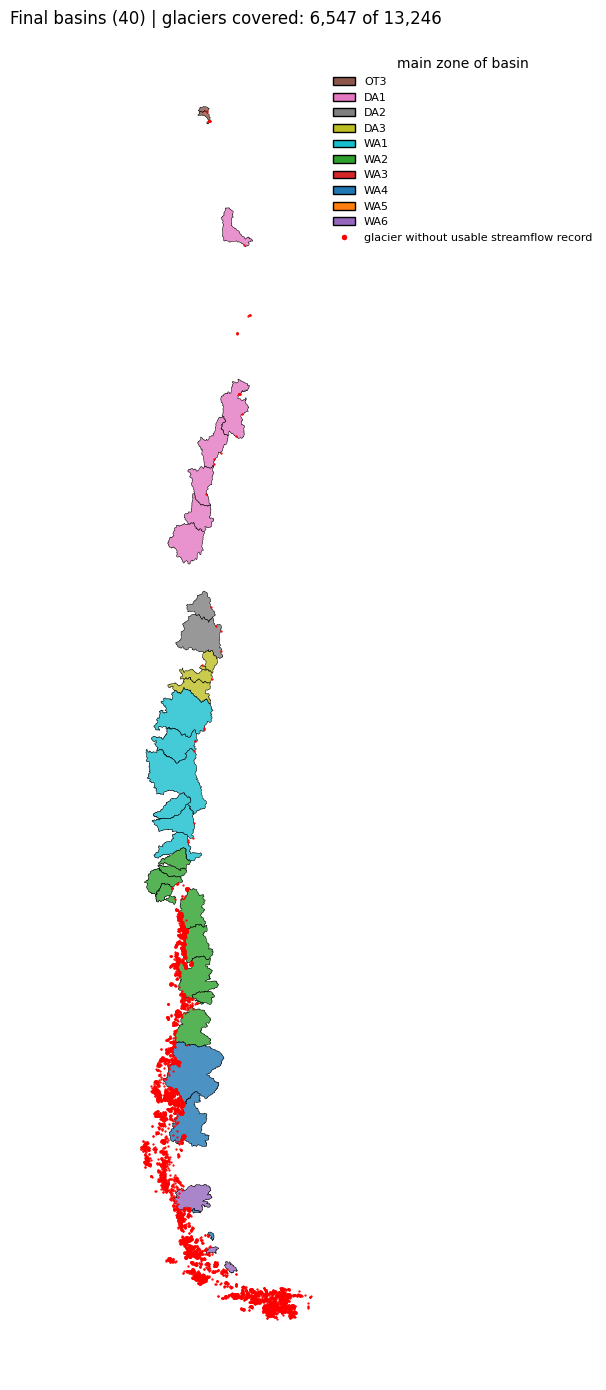

In [12]:
ZOOM = None     # None = all of Chile

geom = cm.set_index('gauge_id').geometry
unit_gdf = gpd.GeoDataFrame(final_table[['gauge_id', 'zone']],
                            geometry=[geom[u] for u in final_table['gauge_id']], crs=AREA_CRS)
uncovered = gl.loc[gl.index.difference(list(ids))]

sel = gl[gl['Cluster'].isin(ZOOM)] if ZOOM else gl
minx, miny, maxx, maxy = sel.total_bounds
px, py = (maxx - minx) * 0.05, (maxy - miny) * 0.05

fig, ax = plt.subplots(figsize=(6, 14) if not ZOOM else (8, 10))
unit_gdf.plot(ax=ax, color=unit_gdf['zone'].map(ZC), edgecolor='k', lw=0.3, alpha=0.8)
uncovered.plot(ax=ax, color='red', markersize=0.4)
ax.set_xlim(minx - px, maxx + px)
ax.set_ylim(miny - py, maxy + py)
ax.set_axis_off()
ax.set_title(f'Final basins ({len(units)}) | glaciers covered: {len(ids):,} of {len(gl):,}')
ax.legend(handles=[Patch(facecolor=ZC[z], edgecolor='k', label=z) for z in ZONES] +
          [Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=5, label='glacier without usable streamflow record')],
          title='main zone of basin', loc='upper left', bbox_to_anchor=(1.02, 1.0),
          fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/final_basins_map.png', dpi=200, bbox_inches='tight')
plt.show()

## 12. Save

Notebook 03 and later read these files instead of rebuilding the basin set.
- `final_basin_table.csv`: one row per final basin.
- `glacier_assignment.csv`: one row per covered glacier (RGIId, basin, zone, area, terminus type).
- `final_basins.gpkg`: basin polygons (Albers projection) with the same columns as the table.

In [13]:
final_table.to_csv(f'{OUT_DIR}/final_basin_table.csv', index=False)

assign = []
for u in units:
    sub = gl.loc[members.get(u, []), ['RGIId', 'Cluster', 'Area', 'TermType']].copy()
    sub.insert(1, 'gauge_id', u)
    assign.append(sub)
assign = pd.concat(assign, ignore_index=True)
assign.to_csv(f'{OUT_DIR}/glacier_assignment.csv', index=False)

out_gdf = gpd.GeoDataFrame(final_table, geometry=[geom[u] for u in final_table['gauge_id']], crs=AREA_CRS)
out_gdf.to_file(f'{OUT_DIR}/final_basins.gpkg', driver='GPKG')

print(f'Saved to {OUT_DIR}:')
print(f'  final_basin_table.csv   ({len(final_table)} basins)')
print(f'  glacier_assignment.csv  ({len(assign):,} glaciers, {assign["RGIId"].nunique():,} unique)')
print(f'  final_basins.gpkg')

Saved to /Users/milliespencer/v2_CR2_OGGM_project_11_2026/Output/final_basin_set:
  final_basin_table.csv   (40 basins)
  glacier_assignment.csv  (6,547 glaciers, 6,547 unique)
  final_basins.gpkg


#### quick final figure check: 

In [14]:
# share of glaciers covered if only the finest (non-nested) basins with usable gauges were used
finest_ok = finest & valid_final
fin_ids = {g for u in finest_ok for g in members.get(u, [])}
print(f'Finest basins: {len(finest)} | with usable gauge: {len(finest_ok)}')
print(f'Glaciers covered: {len(fin_ids):,} ({100*len(fin_ids)/len(gl):.1f}% of all) | '
      f'area: {gl.loc[list(fin_ids), "Area"].sum():,.0f} km2 ({100*gl.loc[list(fin_ids), "Area"].sum()/gl["Area"].sum():.1f}%)')

Finest basins: 103 | with usable gauge: 54
Glaciers covered: 2,082 (15.7% of all) | area: 1,461 km2 (5.3%)
